# Prototype C: the pushback wave (where, when, why)
**Question:** Where and when are towns pausing data centers, and what reasons do they give?

**Data:** Moratorium Nation local moratorium inventory (CC BY 4.0), filtered to moratoria that cover data centers and were adopted (proposals and defeated proposals dropped). Grey dots are the project data center database for context.

**What this can show:** where local pauses cluster, how fast they spread, and which reasons local governments cite.
**What it can't:** what residents think (these are the reasons written into the official action), or whether the concerns are true (that is what the water, price and grid prototypes test).

Caveats carried onto the page:
- Points are a reference point for the town or county, not the data center site.
- 72% of rows carry at least one `[VERIFY]` flag from the dataset author.
- Only May to July 2026 was searched state by state, month by month. Earlier months were searched less systematically, so part of the 2026 rise may be search effort.
- One moratorium can cite several reasons, so reason shares add up to more than 100%.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name in ("data", "jppolizzi", "pnidadavolu") else Path.cwd()
sys.path[:0] = [str(ROOT / ".pylibs"), str(ROOT / "scripts")]
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
CLEAN = ROOT / "data" / "clean"
TODAY = pd.Timestamp("2026-11-15")  # snapshot date for "still in effect" and "upcoming"

m = pd.read_csv(CLEAN / "moratoria_local.csv", parse_dates=["date_enacted", "current_end_date"], dtype={"county_geoid": str})
a = m[m.adopted].copy()   # drop proposals (pending), defeated proposals (rejected) and unknown status

# Palette: categorical slots in fixed order (validated: CVD and normal-vision pass; aqua/yellow need direct labels).
INK, INK2, GRID, AXIS, SURF = "#0b0b0b", "#52514e", "#e1e0d9", "#c3c2b7", "#fcfcfb"
BLUE, ORANGE, AQUA, YELLOW, NEUTRAL = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#a9a89f"
plt.rcParams.update({"font.size": 10, "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "xtick.color": INK2,
                     "ytick.color": INK2, "axes.titlecolor": INK, "figure.facecolor": SURF, "axes.facecolor": SURF})
import geopandas as gpd

geo = gpd.read_file(CLEAN / "counties_simplified.geojson")
geo["st"] = geo["geoid"].str[:2]
conus = geo[~geo["st"].isin(["02", "15", "72"])]
states = conus.dissolve("st").to_crs("EPSG:5070")
dc = pd.read_csv(CLEAN / "datacenters.csv")
dc = dc[dc.coord_ok & ~dc.state.isin(["AK", "HI", "PR"])]

def period(d):
    if pd.isna(d): return "no month-level date"
    if d.year < 2026: return "2025 or earlier"
    return "2026 Jan-Jun" if d.month <= 6 else "2026 Jul-Nov"
a["period"] = a["date_enacted"].map(period)
print(f"{len(m)} data center moratoria in the inventory; {len(a)} adopted; {int(a.date_enacted.notna().sum())} with a month-level date")
print(a["period"].value_counts().to_dict())

1101 data center moratoria in the inventory; 1036 adopted; 971 with a month-level date
{'2026 Jan-Jun': 480, '2026 Jul-Nov': 412, '2025 or earlier': 79, 'no month-level date': 65}


## When: adoptions by quarter

In [2]:
q = a.dropna(subset=["date_enacted"]).groupby(a["date_enacted"].dt.to_period("Q")).size()
display(q.rename("adopted").to_frame().T)
share26 = (a["date_enacted"].dt.year == 2026).sum() / a["date_enacted"].notna().sum()
print(f"{share26:.0%} of dated adoptions are from 2026. 2026 Q4 runs only to the snapshot date.")

date_enacted,2018Q1,2018Q2,2022Q2,2022Q3,2023Q2,2023Q4,2024Q3,2024Q4,2025Q1,2025Q2,2025Q3,2025Q4,2026Q1,2026Q2,2026Q3,2026Q4
adopted,2,1,1,1,3,1,6,2,5,8,15,34,149,331,393,19


92% of dated adoptions are from 2026. 2026 Q4 runs only to the snapshot date.


## Where: top states (adopted moratoria)

In [3]:
top = a["state"].value_counts().head(10)
display(top.rename("adopted").to_frame().T)
print(f"Top 3 states hold {top.head(3).sum() / len(a):.0%} of adopted moratoria.")

state,OH,MI,GA,NC,IA,TN,WI,FL,KY,IN
adopted,158,128,71,61,44,39,39,32,31,28


Top 3 states hold 34% of adopted moratoria.


## Why: share citing each reason, by period
`regulatory_gap` ("we need time to write rules") appears on almost every row, so the chart focuses on the reasons that name a harm.

In [4]:
R = {"water": "Water", "grid_energy": "Grid and energy", "land_use_compatibility": "Land use fit", "noise": "Noise"}
t = a[a["date_enacted"] >= "2025-01-01"].copy()
t["per"] = np.where(t["date_enacted"].dt.year < 2026, "2025", "2026 Q" + t["date_enacted"].dt.quarter.astype(str))
PER = ["2025", "2026 Q1", "2026 Q2", "2026 Q3"]          # 2026 Q4 is partial (to the snapshot date), shown in the table only
shares = t.groupby("per")[[f"reason_{k}" for k in R]].mean().mul(100)
shares.columns = list(R.values())
shares["n"] = t.groupby("per").size()
display(shares.round(0))
print("Overall (all adopted):", a[[f"reason_{k}" for k in [*R, "regulatory_gap"]]].mean().mul(100).round(0).to_dict())

,Water,Grid and energy,Land use fit,Noise,n
per,,,,,
2025,34.0,37.0,77.0,34.0,62
2026 Q1,38.0,35.0,48.0,24.0,149
2026 Q2,25.0,27.0,27.0,14.0,331
2026 Q3,42.0,39.0,24.0,22.0,393
2026 Q4,53.0,53.0,5.0,21.0,19


Overall (all adopted): {'reason_water': 34.0, 'reason_grid_energy': 34.0, 'reason_land_use_compatibility': 31.0, 'reason_noise': 20.0, 'reason_regulatory_gap': 90.0}


## Static figure for the proposal (saved as an image)

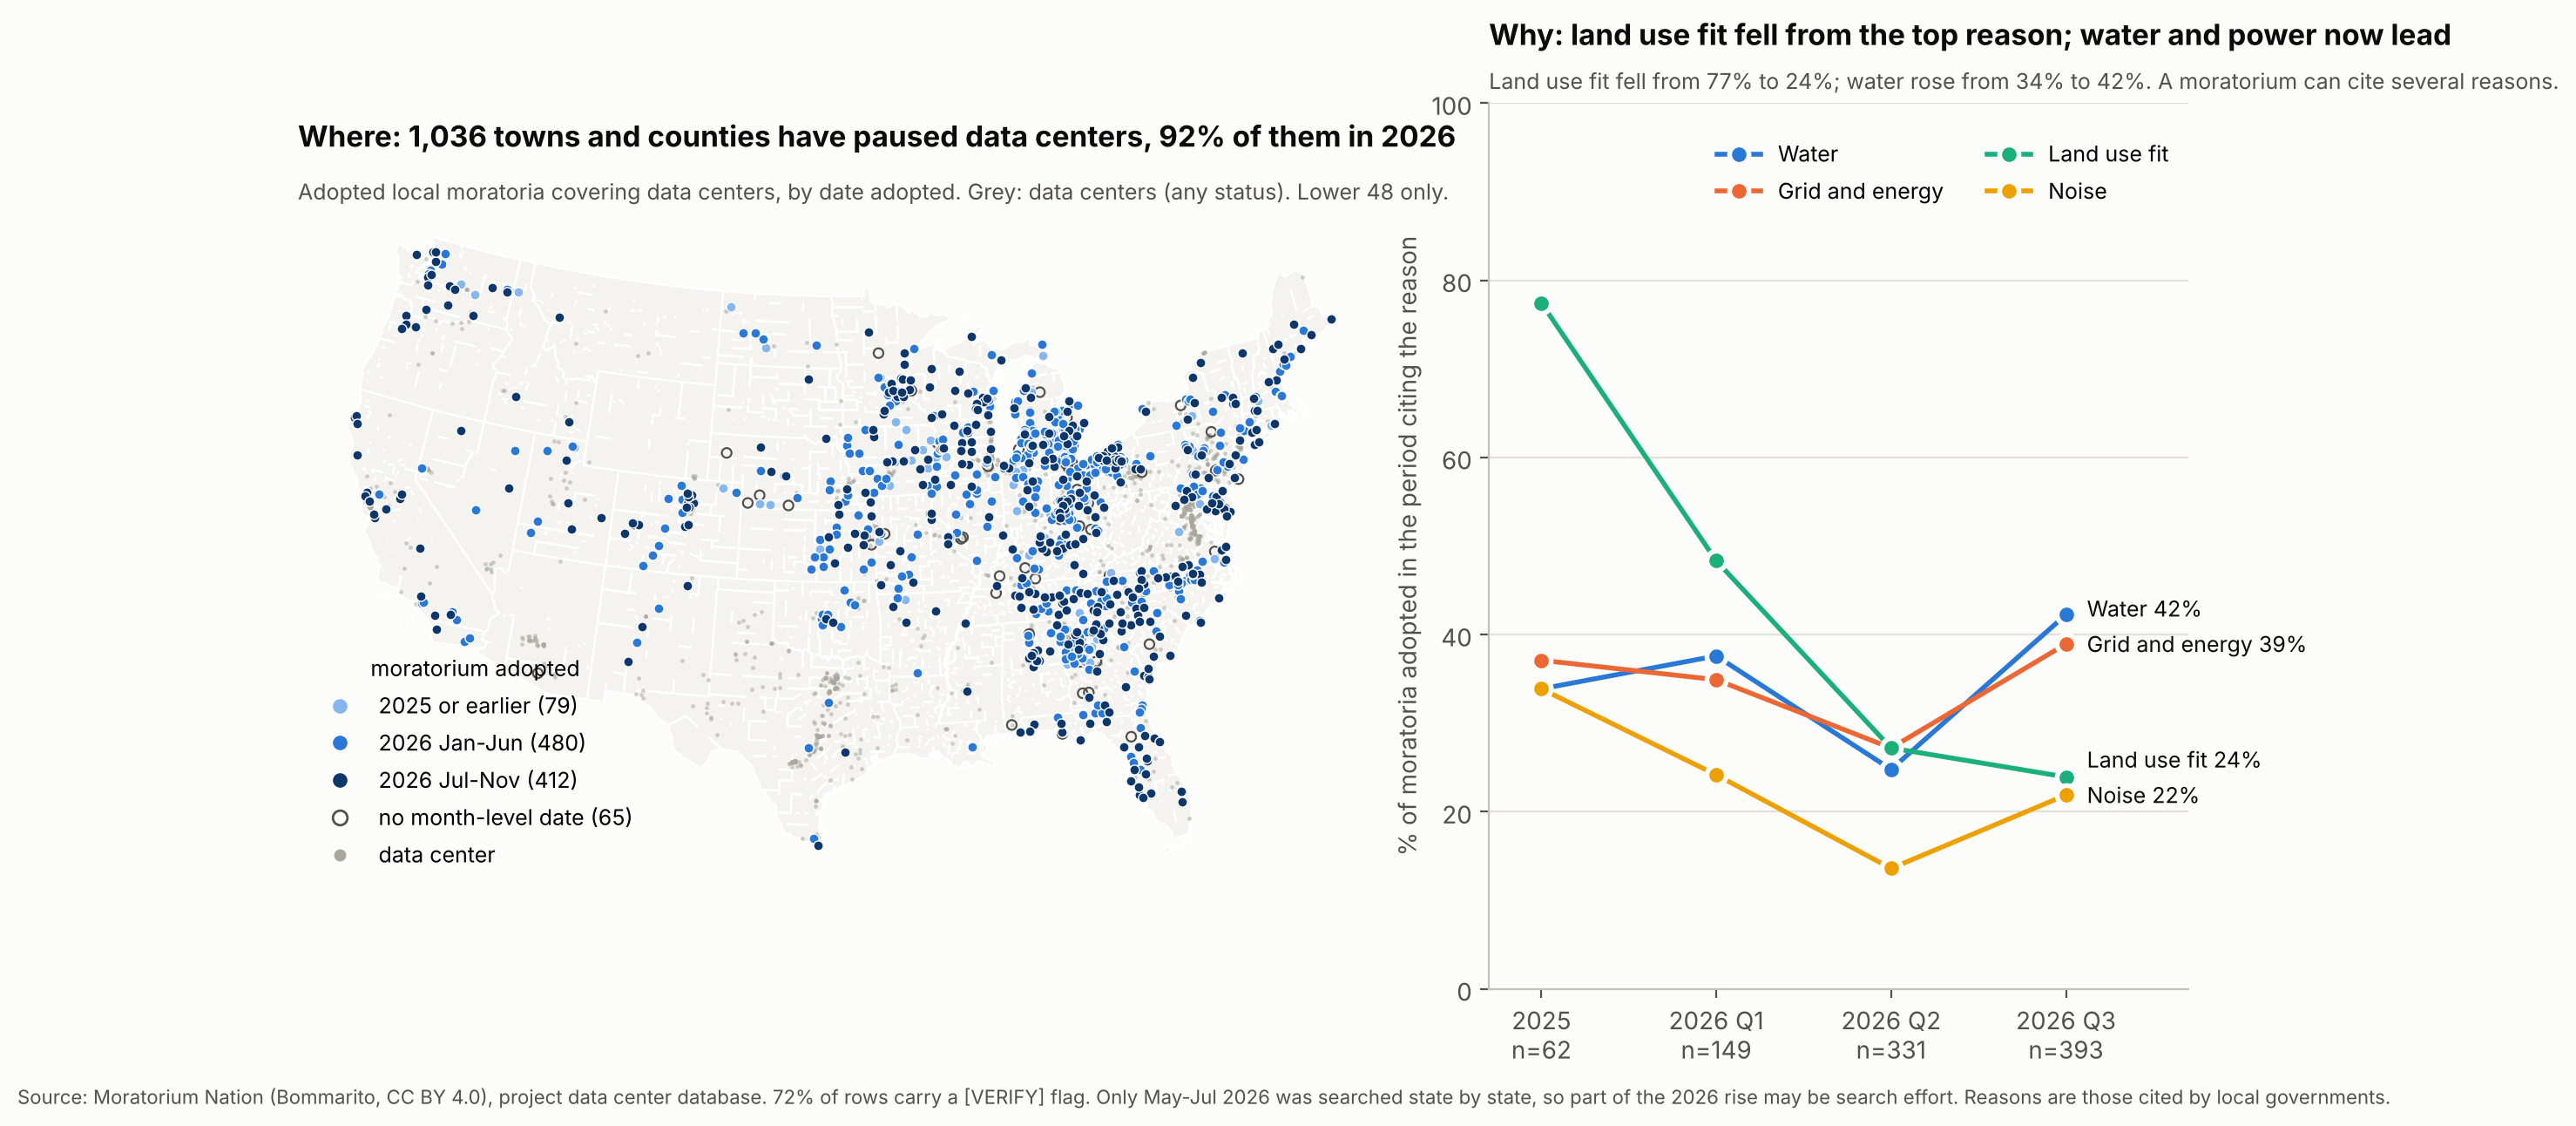

In [5]:
from matplotlib.lines import Line2D
fig = plt.figure(figsize=(14, 6.6))
gs = fig.add_gridspec(1, 2, width_ratios=[1.55, 1], wspace=0.12)

# Left: map
ax = fig.add_subplot(gs[0, 0])
states.plot(ax=ax, facecolor="#f4f3ef", edgecolor="#ffffff", linewidth=0.8)
p = gpd.GeoSeries(gpd.points_from_xy(dc.lon, dc.lat), crs="EPSG:4326").to_crs("EPSG:5070")
ax.scatter(p.x, p.y, s=3, color=NEUTRAL, alpha=0.55, linewidths=0, zorder=2)
mm = a[a.lat.notna() & ~a.state.isin(["AK", "HI"])]
pts = gpd.GeoSeries(gpd.points_from_xy(mm.lon, mm.lat), crs="EPSG:4326").to_crs("EPSG:5070")
COL = {"2025 or earlier": "#86b6ef", "2026 Jan-Jun": "#2a78d6", "2026 Jul-Nov": "#0d366b", "no month-level date": NEUTRAL}
for k in ["no month-level date", "2025 or earlier", "2026 Jan-Jun", "2026 Jul-Nov"]:
    s = (mm["period"] == k).values
    if k == "no month-level date":
        ax.scatter(pts.x[s], pts.y[s], s=16, facecolors="none", edgecolors=INK2, linewidths=0.8, zorder=3)
    else:
        ax.scatter(pts.x[s], pts.y[s], s=16, color=COL[k], edgecolors=SURF, linewidths=0.5, zorder=3)
ax.set_axis_off()
n_early = int((a.period == "2025 or earlier").sum())
ax.set_title(f"Where: {len(a):,} towns and counties have paused data centers, {share26:.0%} of them in 2026", loc="left", fontsize=12, fontweight="bold", pad=24)
ax.text(0, 1.0, "Adopted local moratoria covering data centers, by date adopted. Grey: data centers (any status). Lower 48 only.",
        transform=ax.transAxes, color=INK2, fontsize=9, va="bottom")
h = [Line2D([], [], marker="o", ls="", color=COL[k], markeredgecolor=SURF, markersize=7, label=f"{k} ({int((a.period == k).sum())})")
     for k in ["2025 or earlier", "2026 Jan-Jun", "2026 Jul-Nov"]]
h.append(Line2D([], [], marker="o", ls="", markerfacecolor="none", markeredgecolor=INK2, markersize=6,
                label=f"no month-level date ({int((a.period == 'no month-level date').sum())})"))
h.append(Line2D([], [], marker="o", ls="", color=NEUTRAL, markersize=4, label="data center"))
ax.legend(handles=h, loc="lower left", frameon=False, fontsize=9, title="moratorium adopted", title_fontsize=9)

# Right: reasons over time
bx = fig.add_subplot(gs[0, 1])
x = np.arange(len(PER))
COLS = dict(zip(R.values(), [BLUE, ORANGE, AQUA, YELLOW]))
ends = {}
for name, c in COLS.items():
    y = shares.loc[PER, name].values
    bx.plot(x, y, color=c, lw=2, marker="o", markersize=8, markeredgecolor=SURF, markeredgewidth=2, label=name)
    ends[name] = y[-1]
pos = {}
for name, v in sorted(ends.items(), key=lambda kv: kv[1]):   # keep end labels at least 4 points apart
    pos[name] = max(v, max(pos.values(), default=-99) + 4)
for name, v in ends.items():
    bx.annotate(f"{name} {v:.0f}%", (x[-1], v), xytext=(x[-1] + 0.12, pos[name]), textcoords="data", va="center", color=INK, fontsize=9)
bx.set_xticks(x, [f"{p}\nn={int(shares.loc[p, 'n'])}" for p in PER])
bx.set_xlim(-0.3, len(PER) - 0.3); bx.set_ylim(0, 100)
bx.set_ylabel("% of moratoria adopted in the period citing the reason")
bx.grid(axis="y", color=GRID, lw=0.8); bx.set_axisbelow(True)
for s in ["top", "right"]: bx.spines[s].set_visible(False)
lu0, lu1 = shares.loc["2025", "Land use fit"], shares.loc["2026 Q3", "Land use fit"]
w0, w1 = shares.loc["2025", "Water"], shares.loc["2026 Q3", "Water"]
bx.set_title("Why: land use fit fell from the top reason; water and power now lead", loc="left", fontsize=12, fontweight="bold", pad=24)
bx.text(0, 1.01, f"Land use fit fell from {lu0:.0f}% to {lu1:.0f}%; water rose from {w0:.0f}% to {w1:.0f}%. A moratorium can cite several reasons.",
        transform=bx.transAxes, color=INK2, fontsize=9, va="bottom")
bx.legend(loc="upper right", frameon=False, fontsize=9, ncol=2, bbox_to_anchor=(1.0, 0.98))
fig.text(0.01, 0.01, "Source: Moratorium Nation (Bommarito, CC BY 4.0), project data center database. 72% of rows carry a [VERIFY] flag. "
         "Only May-Jul 2026 was searched state by state, so part of the 2026 rise may be search effort. Reasons are those cited by local governments.",
         fontsize=8, color=INK2)
fig.savefig(ROOT / "images" / "prototype_c_pushback_wave.png", dpi=160, bbox_inches="tight")
plt.show()

## Interactive prototype (time slider linked to the reasons)
Press play or drag the slider. The map adds each period's moratoria (dark) on top of earlier ones (light), and the bars show the reasons cited in that period, so the reader sees the map fill in and the reasons shift at the same time.

In [6]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots

FR = ["2025", "2026 Q1", "2026 Q2", "2026 Q3", "2026 Q4"]
t["frame"] = t["per"]
RB = {"regulatory_gap": "Need time to write rules", "land_use_compatibility": "Land use fit", "water": "Water",
      "grid_energy": "Grid and energy", "noise": "Noise", "infrastructure_capacity": "Roads, sewer, capacity",
      "environmental": "Environment", "specific_project": "A specific project"}
names = {k: v for k, v in RB.items()}
def hover(d):
    rs = d[[f"reason_{k}" for k in RB]].apply(lambda r: ", ".join(names[c[7:]] for c, v in r.items() if v) or "none coded", axis=1)
    return (d["jurisdiction"] + ", " + d["state"] + "<br>adopted " + d["date_enacted"].dt.strftime("%b %Y") +
            "<br>status: " + d["enacted_status"] + "<br>reasons: " + rs)
def frame_data(i):
    now, before = t[t.frame == FR[i]], t[t.frame.isin(FR[:i])]
    sh = [float(v) for v in now[[f"reason_{k}" for k in RB]].mean().mul(100).fillna(0)]  # plain lists: animated frames mis-decode binary arrays
    return [
        go.Scattergeo(lon=before.lon.tolist(), lat=before.lat.tolist(), text=hover(before).tolist(), hovertemplate="%{text}<extra></extra>", mode="markers",
                      marker=dict(size=6, color="#b7d3f6", line=dict(width=0)), name="earlier"),
        go.Scattergeo(lon=now.lon.tolist(), lat=now.lat.tolist(), text=hover(now).tolist(), hovertemplate="%{text}<extra></extra>", mode="markers",
                      marker=dict(size=8, color=BLUE, line=dict(width=1, color=SURF)), name="adopted this period"),
        go.Bar(x=sh, y=list(RB.values()), orientation="h", marker_color=BLUE, text=[f"{v:.0f}%" for v in sh], textposition="outside",
               hovertemplate="%{y}: %{x:.0f}% of this period's moratoria<extra></extra>", showlegend=False),
    ]

fig = make_subplots(rows=1, cols=2, column_widths=[0.64, 0.36], specs=[[{"type": "scattergeo"}, {"type": "bar"}]], horizontal_spacing=0.16,
                    subplot_titles=("", "Reasons cited in this period"))
fig.add_trace(go.Scattergeo(lon=dc.lon, lat=dc.lat, mode="markers", marker=dict(size=3, color=NEUTRAL, opacity=0.5),
                            hoverinfo="skip", name="data center"), 1, 1)
for tr in frame_data(0):
    fig.add_trace(tr, 1, 1 if tr.type == "scattergeo" else 2)
fig.frames = [go.Frame(name=f, data=frame_data(i), traces=[1, 2, 3],
                       layout=dict(title_text=f"Data center moratoria adopted through {f}: {int(t.frame.isin(FR[:i + 1]).sum())}"))
              for i, f in enumerate(FR)]
fig.update_layout(height=600, margin=dict(l=10, r=10, t=70, b=10), paper_bgcolor=SURF, plot_bgcolor=SURF,
    title=dict(text=f"Data center moratoria adopted through {FR[0]}: {int((t.frame == FR[0]).sum())}", x=0.01),
    geo=dict(scope="usa", projection=dict(type="albers usa"), showland=True, landcolor="#f4f3ef", subunitcolor="#ffffff"),
    xaxis=dict(range=[0, 115], showgrid=True, gridcolor=GRID, title="% of the period's moratoria"), yaxis=dict(autorange="reversed"),
    legend=dict(x=0.01, y=0.02, bgcolor="rgba(252,252,251,0.85)"),
    sliders=[dict(active=0, x=0.05, len=0.9, y=-0.02, currentvalue=dict(prefix="Period: "),
                  steps=[dict(label=f, method="animate", args=[[f], dict(mode="immediate", frame=dict(duration=600, redraw=True))]) for f in FR])],
    updatemenus=[dict(type="buttons", x=0.0, y=-0.02, xanchor="right", showactive=False,
                      buttons=[dict(label="Play", method="animate", args=[None, dict(frame=dict(duration=1200, redraw=True), fromcurrent=True)])])])
fig.write_html(ROOT / "pnidadavolu" / "prototype_c_pushback_wave.html", include_plotlyjs=True, auto_play=False, config={"displayModeBar": False})
print("2026 Q4 is partial:", int((t.frame == "2026 Q4").sum()), "moratoria so far")

2026 Q4 is partial: 19 moratoria so far


Saved as `pnidadavolu/prototype_c_pushback_wave.html`.

Next for the D3 version:
- Guess first: the reader clicks the region they think pushes back most before the slider plays.
- Click a reason bar to highlight only the towns that cited it.
- Hand off to the water, price and grid prototypes: "towns say water; here is what the water data shows." 